# 03 · Destilación: de un profesor de Hugging Face a un estudiante diminuto (sentimiento)

**Objetivo de este cuaderno:** repetir la destilación en un problema de lenguaje, con un profesor **ya entrenado** que no vamos a retocar. El profesor es un DistilBERT público, afinado en SST-2 (frases en inglés, positivo / negativo). El estudiante es un GRU bidireccional muy pequeño, con la misma tokenización que el profesor, que cabe y entrena en CPU.

Este es el patrón habitual en producción: el profesor es un modelo de Hugging Face (o uno propio, ya validado); el estudiante es lo que se desplegará en el camino de la petición.

## Diseño

| Pieza | Qué es |
|---|---|
| Profesor | `distilbert-base-uncased-finetuned-sst-2-english` (solo inferencia) |
| Datos | SST-2 (GLUE): 3 000 frases de train y el validation oficial (872) como test |
| Estudiante duro | Embedding + GRU bidireccional + lineal, etiquetas 0/1 |
| Estudiante destilado | La misma arquitectura y los mismos pesos iniciales, \(T=3\), \(\alpha=0.7\) |

Para no tener el DistilBERT en memoria durante el entrenamiento del estudiante, se **precomputan** sus logits, se guardan en disco y se libera el profesor. El estudiante, más adelante, solo alinea esos logits por el índice del ejemplo.


In [1]:
from pathlib import Path
import os, sys, json, time, gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "destilacion_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de destilacion "
        "(src/destilacion_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from destilacion_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    softmax_temperatura,
    divergencia_kl,
    perdida_destilacion,
    construir_mlp,
    construir_estudiante_sentimiento,
    contar_parametros,
    tamano_archivo_mb,
    guardar_json,
    cargar_json,
    guardar_checkpoint,
    cargar_checkpoint,
    evaluar_loader,
    medir_latencia_ms,
    entrenar_epoca,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/destilacion/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raiz:        /workspace/destilacion
Dispositivo: cpu
Semilla:     42


## 1. Parámetros


In [2]:
import torch
from torch import optim
from torch.utils.data import DataLoader, Dataset
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer

MODELO_PROFESOR = "distilbert-base-uncased-finetuned-sst-2-english"
N_TRAIN = 3_000
MAX_LEN = 64
BATCH_PROFESOR = 16
BATCH_ESTUDIANTE = 32
EPOCHS_ESTUDIANTE = 5
T_DISTIL = 3.0
ALPHA = 0.7
LR_ESTUDIANTE = 1e-3
DIM_EMB = 64
DIM_OCULTA = 64
N_CAPAS = 1

print("dispositivo:", DEVICE)
print("profesor:", MODELO_PROFESOR)
print(f"datos: train={N_TRAIN}, max_len={MAX_LEN}")
print(f"estudiante: emb={DIM_EMB}, hidden={DIM_OCULTA}, épocas={EPOCHS_ESTUDIANTE}")
print(f"destilación: T={T_DISTIL}, alpha={ALPHA}")


dispositivo: cpu
profesor: distilbert-base-uncased-finetuned-sst-2-english
datos: train=3000, max_len=64
estudiante: emb=64, hidden=64, épocas=5
destilación: T=3.0, alpha=0.7


## 2. Datos SST-2 y tokenizador del profesor

SST-2 es binario (0 = negativo, 1 = positivo). El conjunto se carga desde `nyu-mll/glue` (el identificador antiguo `glue` ya no es válido en el Hub). El *split* de test oficial de GLUE no trae etiquetas públicas, así que usamos el **validation** como conjunto de evaluación (872 frases). No se toca para elegir hiperparámetros: en este cuaderno no hay búsqueda, solo una comparación honesta entre dos estudiantes.

El estudiante reutiliza el **mismo tokenizador** que el profesor. Así, lo que ve el profesor y lo que ve el estudiante es la misma secuencia de identificadores. En producción, ese tokenizador tiene que viajar con el estudiante (es parte del preprocesamiento).


In [3]:
# Caché del proyecto (HF_HOME ya apunta a cache-hf/ si no había otro).
ds = load_dataset("nyu-mll/glue", "sst2")

g = torch.Generator().manual_seed(SEMILLA)
idx = torch.randperm(len(ds["train"]), generator=g).tolist()[:N_TRAIN]
textos_train = [ds["train"][i]["sentence"] for i in idx]
y_train = [int(ds["train"][i]["label"]) for i in idx]
textos_test = list(ds["validation"]["sentence"])
y_test = [int(v) for v in ds["validation"]["label"]]

print(f"train={len(textos_train)}  test={len(textos_test)}")
print("ejemplo train:", textos_train[0], "→", y_train[0])
print("clases train:  neg=", sum(v == 0 for v in y_train), " pos=", sum(v == 1 for v in y_train))
print("clases test:   neg=", sum(v == 0 for v in y_test), " pos=", sum(v == 1 for v in y_test))

tokenizer = AutoTokenizer.from_pretrained(MODELO_PROFESOR)


def tokenizar(textos):
    enc = tokenizer(
        textos,
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt",
    )
    return {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"]}


enc_train = tokenizar(textos_train)
enc_test = tokenizar(textos_test)


class SentimientoDS(Dataset):
    def __init__(self, enc, etiquetas):
        self.input_ids = enc["input_ids"]
        self.attention_mask = enc["attention_mask"]
        self.labels = torch.tensor(etiquetas, dtype=torch.long)

    def __len__(self):
        return int(self.labels.size(0))

    def __getitem__(self, i):
        return {
            "input_ids": self.input_ids[i],
            "attention_mask": self.attention_mask[i],
            "labels": self.labels[i],
            "idx": i,
        }


ds_train = SentimientoDS(enc_train, y_train)
ds_test = SentimientoDS(enc_test, y_test)
loader_train = DataLoader(ds_train, batch_size=BATCH_ESTUDIANTE, shuffle=True, num_workers=0)
loader_test = DataLoader(ds_test, batch_size=BATCH_ESTUDIANTE, shuffle=False, num_workers=0)
loader_train_ordenado = DataLoader(ds_train, batch_size=BATCH_PROFESOR, shuffle=False, num_workers=0)
loader_test_prof = DataLoader(ds_test, batch_size=BATCH_PROFESOR, shuffle=False, num_workers=0)


train=3000  test=872
ejemplo train: steals the show  → 1
clases train:  neg= 1320  pos= 1680
clases test:   neg= 428  pos= 444


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

## 3. Profesor: cargar, evaluar y precomputar logits

La primera ejecución descarga el modelo al caché del proyecto (del orden de 250 MB). Después se reutiliza, incluso sin red si defines `HF_HUB_OFFLINE=1`.


In [4]:
profesor = AutoModelForSequenceClassification.from_pretrained(MODELO_PROFESOR)
profesor.to(DEVICE)
profesor.eval()
for p in profesor.parameters():
    p.requires_grad_(False)

n_prof = contar_parametros(profesor)
print(f"parámetros del profesor: {n_prof:,}")
print("etiquetas:", profesor.config.id2label)


def logits_de(loader, modelo):
    partes = []
    aciertos = 0
    total = 0
    with torch.no_grad():
        for lote in loader:
            ids = lote["input_ids"].to(DEVICE)
            mask = lote["attention_mask"].to(DEVICE)
            y = lote["labels"].to(DEVICE)
            logits = modelo(input_ids=ids, attention_mask=mask).logits
            partes.append(logits.cpu())
            aciertos += int((logits.argmax(dim=-1) == y).sum().item())
            total += int(y.size(0))
    return torch.cat(partes, dim=0), aciertos / max(total, 1)


print("Inferencia del profesor (una pasada por train y test)...")
t0 = time.perf_counter()
logits_train, acc_prof_train = logits_de(loader_train_ordenado, profesor)
logits_test, acc_prof_test = logits_de(loader_test_prof, profesor)
seg = time.perf_counter() - t0
print(f"listo en {seg:.1f} s  exactitud profesor: train={acc_prof_train:.3f}  test={acc_prof_test:.3f}")

ruta_logits = RUTAS["modelos"] / "sentimiento_logits_profesor.pt"
torch.save(
    {
        "train": logits_train,
        "test": logits_test,
        "modelo": MODELO_PROFESOR,
        "idx_train": idx,
        "semilla": SEMILLA,
    },
    ruta_logits,
)

# Latencia del profesor (lote de 16) antes de liberarlo.
lote_ej = next(iter(loader_test_prof))
# medir_latencia_ms espera un dict con input_ids; el wrapper del profesor de HF
# no es el mismo que el del estudiante. Medimos a mano.


def latencia_hf(modelo, lote, n_cal=5, n_reps=20):
    modelo.eval()
    ids = lote["input_ids"][:16].to(DEVICE)
    mask = lote["attention_mask"][:16].to(DEVICE)
    with torch.no_grad():
        for _ in range(n_cal):
            modelo(input_ids=ids, attention_mask=mask)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        tiempos = []
        for _ in range(n_reps):
            t1 = time.perf_counter()
            modelo(input_ids=ids, attention_mask=mask)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            tiempos.append((time.perf_counter() - t1) * 1000.0)
    arr = np.asarray(tiempos)
    return {
        "ms_lote_media": float(arr.mean()),
        "ms_lote_p50": float(np.percentile(arr, 50)),
        "ms_lote_p95": float(np.percentile(arr, 95)),
        "ms_por_ejemplo_media": float(arr.mean() / ids.size(0)),
        "n_reps": n_reps,
        "tamano_lote": int(ids.size(0)),
    }


lat_prof = latencia_hf(profesor, lote_ej)
print("latencia profesor:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in lat_prof.items()})

# Liberar memoria: a partir de aquí solo viven los logits.
del profesor
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print("Profesor liberado de memoria. Logits guardados en", ruta_logits)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

parámetros del profesor: 66,955,010
etiquetas: {0: 'NEGATIVE', 1: 'POSITIVE'}
Inferencia del profesor (una pasada por train y test)...


listo en 24.8 s  exactitud profesor: train=0.987  test=0.911


latencia profesor: {'ms_lote_media': 139.109, 'ms_lote_p50': 127.717, 'ms_lote_p95': 233.252, 'ms_por_ejemplo_media': 8.694, 'n_reps': 20, 'tamano_lote': 16}
Profesor liberado de memoria. Logits guardados en /workspace/destilacion/modelos/sentimiento_logits_profesor.pt


## 4. Estudiante diminuto

El estudiante no es un transformer: es un embedding + GRU bidireccional + una capa lineal. El vocabulario es el del profesor (unos 30 000 tokens), así que casi todos sus parámetros están en la matriz de embeddings. Aun así, queda en torno a **2 millones** de parámetros frente a los **66 millones** del DistilBERT: un orden de magnitud menor, y mucho más barato de ejecutar.


In [5]:
pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
vocab = len(tokenizer)

fijar_semilla(SEMILLA)
plantilla = construir_estudiante_sentimiento(
    vocab_size=vocab,
    n_clases=2,
    dim_emb=DIM_EMB,
    dim_oculta=DIM_OCULTA,
    n_capas=N_CAPAS,
    pad_id=pad_id,
).to(DEVICE)
estado_inicial = {k: v.detach().cpu().clone() for k, v in plantilla.state_dict().items()}
n_est = contar_parametros(plantilla)
print(f"parámetros del estudiante: {n_est:,}  ({n_est / n_prof:.1%} del profesor)")
print("config:", plantilla.config)


def entrenar_estudiante(modelo, usar_destilacion, etiqueta):
    opt = optim.Adam(modelo.parameters(), lr=LR_ESTUDIANTE)
    historial = []
    for epoca in range(1, EPOCHS_ESTUDIANTE + 1):
        tr = entrenar_epoca(
            modelo,
            loader_train,
            opt,
            DEVICE,
            logits_profesor=logits_train if usar_destilacion else None,
            temperature=T_DISTIL,
            alpha=ALPHA if usar_destilacion else 0.0,
            indices_en_lote=True,
        )
        ev = evaluar_loader(modelo, loader_test, DEVICE)
        fila = {
            "epoca": epoca,
            "train_perdida": tr["perdida"],
            "train_exactitud": tr["exactitud"],
            "test_exactitud": ev["exactitud"],
            "test_perdida": ev["perdida_ce"],
        }
        historial.append(fila)
        print(
            f"{etiqueta:22s} época {epoca:2d}/{EPOCHS_ESTUDIANTE}  "
            f"train acc={tr['exactitud']:.3f}  test acc={ev['exactitud']:.3f}  "
            f"pérdida={tr['perdida']:.3f}"
        )
    return historial


estudiante_duro = construir_estudiante_sentimiento(
    vocab_size=vocab, n_clases=2, dim_emb=DIM_EMB, dim_oculta=DIM_OCULTA,
    n_capas=N_CAPAS, pad_id=pad_id,
).to(DEVICE)
estudiante_duro.load_state_dict(estado_inicial)
hist_duro = entrenar_estudiante(estudiante_duro, usar_destilacion=False, etiqueta="estudiante duro")

estudiante_kd = construir_estudiante_sentimiento(
    vocab_size=vocab, n_clases=2, dim_emb=DIM_EMB, dim_oculta=DIM_OCULTA,
    n_capas=N_CAPAS, pad_id=pad_id,
).to(DEVICE)
estudiante_kd.load_state_dict(estado_inicial)
hist_kd = entrenar_estudiante(estudiante_kd, usar_destilacion=True, etiqueta="estudiante destilado")

metricas_duro = evaluar_loader(estudiante_duro, loader_test, DEVICE)
metricas_kd = evaluar_loader(estudiante_kd, loader_test, DEVICE)
print("test duro:", metricas_duro)
print("test destilado:", metricas_kd)
print("test profesor:", acc_prof_test)


parámetros del estudiante: 2,003,586  (3.0% del profesor)
config: {'vocab_size': 30522, 'n_clases': 2, 'dim_emb': 64, 'dim_oculta': 64, 'n_capas': 1, 'pad_id': 0, 'dropout': 0.2, 'arquitectura': 'embedding-gru-bidireccional'}


estudiante duro        época  1/5  train acc=0.547  test acc=0.511  pérdida=0.692


estudiante duro        época  2/5  train acc=0.624  test acc=0.591  pérdida=0.650


estudiante duro        época  3/5  train acc=0.706  test acc=0.609  pérdida=0.561


estudiante duro        época  4/5  train acc=0.791  test acc=0.638  pérdida=0.450


estudiante duro        época  5/5  train acc=0.866  test acc=0.650  pérdida=0.321


estudiante destilado   época  1/5  train acc=0.553  test acc=0.514  pérdida=2.838


estudiante destilado   época  2/5  train acc=0.631  test acc=0.606  pérdida=2.650


estudiante destilado   época  3/5  train acc=0.715  test acc=0.649  pérdida=2.223


estudiante destilado   época  4/5  train acc=0.793  test acc=0.641  pérdida=1.694


estudiante destilado   época  5/5  train acc=0.863  test acc=0.674  pérdida=1.206
test duro: {'exactitud': 0.6502293577981652, 'perdida_ce': 0.8162359885119517, 'n': 872}
test destilado: {'exactitud': 0.6743119266055045, 'perdida_ce': 1.197930276940722, 'n': 872}
test profesor: 0.9105504587155964


## 5. Curvas, ejemplos y artefactos


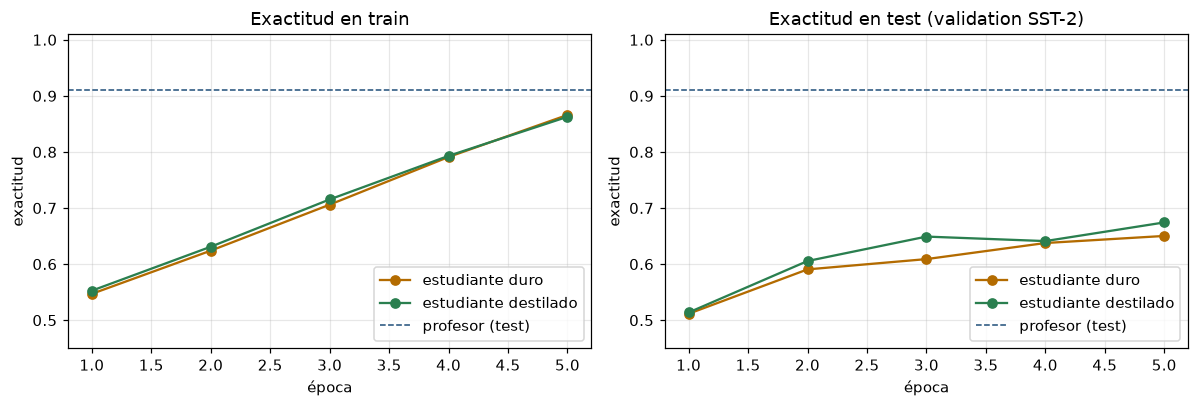

,frase,y,pred_estudiante,p_neg_profesor_T,p_pos_profesor_T
0,it 's a charming and often affecting journey .,1,0,0.047,0.953
1,unflinchingly bleak and desperate,0,0,0.908,0.092
2,allows us to hope that nolan is poised to emba...,1,1,0.066,0.934
3,"the acting , costumes , music , cinematography...",1,0,0.063,0.937
4,"it 's slow -- very , very slow .",0,0,0.937,0.063
5,although laced with humor and a few fanciful t...,1,1,0.053,0.947


In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for hist, nombre, color in [
    (hist_duro, "estudiante duro", "#b36b00"),
    (hist_kd, "estudiante destilado", "#2a7f4f"),
]:
    ep = [f["epoca"] for f in hist]
    ejes[0].plot(ep, [f["train_exactitud"] for f in hist], marker="o", label=nombre, color=color)
    ejes[1].plot(ep, [f["test_exactitud"] for f in hist], marker="o", label=nombre, color=color)
for ax in ejes:
    ax.axhline(acc_prof_test, color="#1f4e79", linestyle="--", linewidth=1, label="profesor (test)")
    ax.set_xlabel("época")
    ax.set_ylabel("exactitud")
    ax.set_ylim(0.45, 1.01)
    ax.legend()
ejes[0].set_title("Exactitud en train")
ejes[1].set_title("Exactitud en test (validation SST-2)")
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_sentimiento_curvas.png", bbox_inches="tight")
plt.show()

# Algunas frases: etiqueta real, predicción del estudiante destilado, y blandas del profesor.
estudiante_kd.eval()
n_show = 6
with torch.no_grad():
    lote = {k: v[:n_show] if torch.is_tensor(v) else v for k, v in next(iter(loader_test)).items()}
    pred = estudiante_kd(lote["input_ids"].to(DEVICE), lote["attention_mask"].to(DEVICE)).argmax(dim=-1).cpu()
    blandas = softmax_temperatura(logits_test[:n_show].numpy(), temperature=T_DISTIL)

filas = []
for i in range(n_show):
    filas.append(
        {
            "frase": textos_test[int(lote["idx"][i])][:80],
            "y": int(lote["labels"][i]),
            "pred_estudiante": int(pred[i]),
            "p_neg_profesor_T": round(float(blandas[i, 0]), 3),
            "p_pos_profesor_T": round(float(blandas[i, 1]), 3),
        }
    )
display(pd.DataFrame(filas))


In [7]:
lote_lat = next(iter(loader_test))
lat_duro = medir_latencia_ms(estudiante_duro, lote_lat, device=DEVICE)
lat_kd = medir_latencia_ms(estudiante_kd, lote_lat, device=DEVICE)

ruta_duro = RUTAS["modelos"] / "sentimiento_estudiante_duro.pt"
ruta_kd = RUTAS["modelos"] / "sentimiento_estudiante_destilado.pt"
meta = {
    "profesor": MODELO_PROFESOR,
    "n_train": N_TRAIN,
    "n_test": len(ds_test),
    "max_len": MAX_LEN,
    "temperature": T_DISTIL,
    "alpha": ALPHA,
    "semilla": SEMILLA,
    "dispositivo": str(DEVICE),
    "arquitectura_estudiante": plantilla.config,
}
guardar_checkpoint(estudiante_duro, ruta_duro, {**meta, "rol": "estudiante_duro", **metricas_duro})
guardar_checkpoint(estudiante_kd, ruta_kd, {**meta, "rol": "estudiante_destilado", **metricas_kd})

resultado = {
    "problema": "sst2-distilbert-a-gru",
    "profesor": MODELO_PROFESOR,
    "semilla": SEMILLA,
    "dispositivo": str(DEVICE),
    "temperature": T_DISTIL,
    "alpha": ALPHA,
    "n_train": N_TRAIN,
    "n_test": len(ds_test),
    "max_len": MAX_LEN,
    "modelos": {
        "profesor": {
            "ruta": MODELO_PROFESOR,
            "parametros": int(n_prof),
            "tamano_mb": None,
            "exactitud": acc_prof_test,
            "exactitud_train": acc_prof_train,
            "n": len(ds_test),
            **{f"latencia_{k}": v for k, v in lat_prof.items()},
        },
        "estudiante_duro": {
            "ruta": str(ruta_duro.relative_to(RAIZ)),
            "parametros": int(n_est),
            "tamano_mb": tamano_archivo_mb(ruta_duro),
            **metricas_duro,
            **{f"latencia_{k}": v for k, v in lat_duro.items()},
        },
        "estudiante_destilado": {
            "ruta": str(ruta_kd.relative_to(RAIZ)),
            "parametros": int(n_est),
            "tamano_mb": tamano_archivo_mb(ruta_kd),
            **metricas_kd,
            **{f"latencia_{k}": v for k, v in lat_kd.items()},
        },
    },
    "historial": {"estudiante_duro": hist_duro, "estudiante_destilado": hist_kd},
}
guardar_json(resultado, RUTAS["resultados"] / "sentimiento.json")

comp = pd.DataFrame(
    [
        {
            "modelo": nombre,
            "parametros": datos["parametros"],
            "tamano_mb": (None if datos.get("tamano_mb") is None else round(datos["tamano_mb"], 3)),
            "exactitud_test": round(datos["exactitud"], 4),
            "ms_por_ejemplo": round(datos["latencia_ms_por_ejemplo_media"], 4),
        }
        for nombre, datos in resultado["modelos"].items()
    ]
)
display(comp)
print("Artefactos escritos en modelos/ y resultados/sentimiento.json")


,modelo,parametros,tamano_mb,exactitud_test,ms_por_ejemplo
0,profesor,66955010,NaN,0.9106,8.6943
1,estudiante_duro,2003586,7.648,0.6502,0.0792
2,estudiante_destilado,2003586,7.648,0.6743,0.0804


Artefactos escritos en modelos/ y resultados/sentimiento.json


## Interpretación y cierre

- El profesor de Hugging Face no se ha reentrenado. En un equipo real eso importa: el profesor puede ser un modelo ya validado, versionado y costoso de volver a mover.
- El estudiante no va a igualar a DistilBERT con 3 000 frases y un GRU de un par de millones de parámetros. El éxito es **acercarse** más que el estudiante duro, con una latencia mucho menor.
- El tokenizador es parte del artefacto. Si en producción alguien tokeniza distinto, el estudiante no está recibiendo lo que aprendió.
- `resultados/sentimiento.json` es la entrada del cuaderno 04, junto con `resultados/mnist.json`.

Siguiente: `04-comparativa-y-produccion.ipynb`.
